# Solar filament instance segmentation: the whole pipeline

## Kaggle submissions

Every Kaggle submission this repository rebuilds, and the configuration that
made it (README, *Published configurations*):

| Kaggle submission | Public score | Configuration | Recipe | Local PQ, report half (TP / FP / FN) | Rebuilt by (notebook stage 2) |
|---|---|---|---|---|---|
| 58242720 | 0.39 | `"013ft"` | YOLO11l-seg at 1792 px, folds 1-4 (`detector_yolo11l_seg_1792.pt`) + fine-tuned refiner (`refiner_native_residual_ft.pt`), alpha 1.0 | 0.4346 (605 / 305 / 386) | `CONFIGURATION = "013ft"` |
| 58242724 | 0.39 | `"035"` | YOLO11l-seg at 1792 px, all 707 images (`detector_yolo11l_seg_1792_full.pt`) + fine-tuned refiner (`refiner_native_residual_ft.pt`), alpha 1.0 | LB-only: detector trained on all 707 training images | `CONFIGURATION = "035"` |
| 58181980 | 0.39 | `"032"` | YOLO11l-seg at 1792 px, all 707 images (`detector_yolo11l_seg_1792_full.pt`) + refiner (`refiner_native_residual.pt`), alpha 1.0 | LB-only: detector trained on all 707 training images | `CONFIGURATION = "032"` |
| 56828482 | 0.38 | `"013"` (default) | YOLO11l-seg at 1792 px, folds 1-4 (`detector_yolo11l_seg_1792.pt`) + refiner (`refiner_native_residual.pt`), alpha 1.0 | 0.4312 (602 / 308 / 389) | `CONFIGURATION = "013"` (as shipped) |
| 58179404 | 0.38 | `"025"` | YOLO11m-seg at 2048 px, NMS IoU 0.0, folds 1-4 (`detector_yolo11m_seg_2048.pt`) + refiner (`refiner_native_residual.pt`), alpha 1.5 | 0.4275 (566 / 236 / 425) | `CONFIGURATION = "025"` |

**Final selections: 58242720 (`"013ft"`) and 58242724 (`"035"`).**

To rebuild a row's CSV, set `CONFIGURATION` in stage 2 below (it ships as
`"013"`) and run every cell; the CSV is written to `outputs/submission.csv`.
*Local PQ* is measured on the report half of validation fold 0 (71 images,
126 annotator records; stage 7). For scale: annotators agree with each other
at 0.342, one annotator against all annotators reaches 0.598, and the union of
all annotators' instances 0.767. *LB-only*: the detector was trained on all
707 training images, so no image is held out from it. The public scores cover
about half of the 180 test images and are shown with two decimals.

## The notebook

This notebook runs every stage from the raw H-alpha frames to `submission.csv`
with the published weights, then measures the model on held-out training
images with the competition's metric and the evaluation committee's criteria.
All logic lives in the `filament` package next to this folder; the notebook
only calls it.

| Stage | What happens | Module |
|---|---|---|
| 1 | environment and package versions | |
| 2 | paths and parameters (relative to the repository) | |
| 3 | test images are loaded; every pipeline setting in one table | `filament.io`, `filament.pipeline` |
| 4 | optional retraining (off by default); weights verified and loaded; inference | `training/`, `filament.pipeline`, `filament.models` |
| 5 | post-processing and validation of the instances | `filament.submission` |
| 6 | `submission.csv` is written | `filament.submission` |
| 7 | validation-set evaluation: the recorded score recomputed and compared; PQ, IoU / Dice distributions, split / merge counts | `filament.folds`, `filament.metric`, `filament.analysis` |
| 8 | figures | `filament.viz` |

**The model.** YOLO11l-seg at 1792 px proposes filaments; a small U-Net then
corrects each proposal's mask on native-resolution tiles (the native residual
refiner). By default nothing is trained: the published weights in `weights/`
are the ones that made the recorded predictions. Retraining both networks is
optional (`RETRAIN = True` in stage 2) and needs one CUDA GPU for about 11
hours (Tesla T4).

**Runtime.** On a laptop CPU (Apple M2, 8 GB) the model takes about 8 s per
frame, so stage 4 (180 test frames) takes about 25 min and stage 7 (71
validation frames) about 10 min; everything else takes about a minute. A CUDA
GPU is used automatically when there is one. `TEST_LIMIT` and
`RECOMPUTE_VALIDATION` in stage 2 shorten a quick look.

Run it from the repository with `jupyter execute notebooks/pipeline.ipynb`,
or open it in Jupyter and run the cells in order.

## 1. Environment

In [1]:
import platform
import sys
from importlib.metadata import version

print("python", sys.version.split()[0], "|", platform.platform())
for package in ("numpy", "pandas", "pycocotools", "opencv-python-headless", "torch", "torchvision",
                "ultralytics", "matplotlib"):
    print(f"{package:24s} {version(package)}")

python 3.10.19 | macOS-26.0.1-arm64-arm-64bit
numpy                    1.26.4
pandas                   2.3.3
pycocotools              2.0.11
opencv-python-headless   4.11.0.86
torch                    2.5.1
torchvision              0.20.1
ultralytics              8.4.126
matplotlib               3.10.9


## 2. Paths and parameters

Every path is relative to the repository root, found by walking up from the
working directory to the folder that contains `filament/`. The competition data
is expected in the layout of the Kaggle Data page, unzipped under `data/`:

```
data/MAGFiLO_1.0_Kaggle_2026/
├── train/
│   ├── MAGFiLO_1.0_Annotations_kaggle2026_train.json
│   └── train_images/<stem>.jpeg      707 frames
└── test/
    └── test_images/<stem>.jpeg       180 frames
```

Set `FILAMENT_DATA_ROOT` to use another location, and `FILAMENT_OUTPUT_DIR` to
write outputs elsewhere than `outputs/`.

In [2]:
import os
from pathlib import Path


def find_repo(start: Path) -> Path:
    for folder in (start, *start.parents):
        if (folder / "filament" / "__init__.py").is_file():
            return folder
    raise FileNotFoundError("run this notebook from inside the repository")


REPO = find_repo(Path.cwd())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

DATA_ROOT = Path(os.environ.get("FILAMENT_DATA_ROOT", REPO / "data" / "MAGFiLO_1.0_Kaggle_2026"))
ANNOTATIONS = DATA_ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
TRAIN_IMAGES = DATA_ROOT / "train" / "train_images"
TEST_IMAGES = DATA_ROOT / "test" / "test_images"
WEIGHTS_DIR = REPO / "weights"
OUTPUT_DIR = Path(os.environ.get("FILAMENT_OUTPUT_DIR", REPO / "outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = None                  # None: the first CUDA GPU if there is one, else the CPU
CONFIGURATION = "013"          # "013": the default model; "025", "032", "013ft" or "035": the others (README)
RETRAIN = False                # True: retrain both networks first (one CUDA GPU, about 11 hours); stage 4
TEST_LIMIT = None              # None: every test image; a number: only the first ones (a quick look)
MIN_AREA = 1                   # pixels; instances smaller than this are dropped

# Stage 7 predicts the 71 report-half images again with the chosen configuration and
# compares the result with what was recorded when it was evaluated: the predictions
# themselves for the default, the score for "025" and "013ft". It does not score "032"
# or "035" (stage 7).
RECOMPUTE_VALIDATION = True    # False: score the recorded predictions only (seconds, not minutes)
VALIDATION_PREDICTIONS = REPO / "predictions" / "validation_yolo11l_residual.json"   # the default's
VALIDATION_RECORDED = {        # each configuration's report half, as recorded when it was evaluated
    "013": {"pq": 0.4312, "tp": 602, "fp": 308, "fn": 389},
    "025": {"pq": 0.427543, "tp": 566, "fp": 236, "fn": 425},
    "032": None,               # no held-out images: its detector was trained on all 707
    "013ft": {"pq": 0.434551, "tp": 605, "fp": 305, "fn": 386},
    "035": None,               # no held-out images: the detector of "032", trained on all 707
}
REPRODUCTION_TOLERANCE = 1e-4  # PQ difference still read as float drift; beyond it stage 7 warns, never stops

# Four report-half images for the overlays: the 5th, 35th, 65th and 95th
# percentile of per-image PQ among images with at least 10 annotated instances.
FIGURE_STEMS = ["20121218063534Lh", "20150518145654Bh", "20171027223030Lh", "20130913142354Bh"]

for name, path in (("annotations", ANNOTATIONS), ("train images", TRAIN_IMAGES),
                   ("test images", TEST_IMAGES), ("weights", WEIGHTS_DIR),
                   ("validation predictions", VALIDATION_PREDICTIONS)):
    print(f"{name:24s} {'found' if path.exists() else 'MISSING'}")

annotations              found
train images             found
test images              found
weights                  found
validation predictions   found


## 3. Test images and the pipeline's settings

Each frame is a 2048 x 2048 single-channel JPEG. `load_image` rejects anything
else, because a resized frame would shift every mask boundary. There is no
other preprocessing step of our own: the detector sees the frame replicated to
three channels, which Ultralytics resizes to 1792 px and scales to [0, 1], and
the refiner computes its four input channels from the native frame around each
proposal. The table lists every setting between the raw frame and the
submitted masks, with where it came from.

In [3]:
from IPython.display import display

from filament import pipeline
from filament.io import list_images, load_image
from filament.models.detector import detector_input
from filament.models.refiner import background_of

test_paths = list_images(TEST_IMAGES)
if TEST_LIMIT is not None:
    test_paths = test_paths[:TEST_LIMIT]
print(f"{len(test_paths)} test images")

sample = test_paths[0] if test_paths else next(iter(list_images(TRAIN_IMAGES)), None)
if sample is None:
    print("no images found; place the competition data as described in stage 2")
else:
    frame = load_image(sample)
    print(f"{sample.stem}: {frame.shape} {frame.dtype}, values {frame.min()}-{frame.max()}")
    print(f"detector input: {detector_input(frame).shape} {detector_input(frame).dtype}")
    print(f"refiner background (Gaussian, sigma {pipeline.REFINER.background_sigma:g} px): "
          f"values {background_of(frame).min()}-{background_of(frame).max()}")

display(pipeline.parameters())

180 test images
20110120105534Ch: (2048, 2048) uint8, values 0-255
detector input: (2048, 2048, 3) uint8
refiner background (Gaussian, sigma 15 px): values 0-174


,stage,parameter,value,note
0,input,frame,"2048 x 2048 uint8, one channel",native resolution; every output mask is predic...
1,detector,channels,gray replicated to 3,byte-identical to Ultralytics reading the JPEG
2,detector,imgsz,1792,frame resized 2048 -> 1792 (bilinear) by Ultra...
3,detector,conf_floor,0.05,Ultralytics conf: proposals kept from here
4,detector,nms_iou,0.5,chosen on the tune half from 0.0 / 0.5 / 0.7
5,detector,max_det,60,proposals per frame at most
6,detector,retina_masks,True,mask logits upsampled to 2048 before thresholding
7,detector,mask_threshold,0.5,probability
8,detector,confidence,0.3,"operating point, chosen on the tune half from ..."
9,refiner,tile,512,"native pixels, no resizing"


## 4. Model: optional retraining, verified weights, inference

### Optional: retraining both networks

The two scripts in `training/` are the training runs that produced the
published weights, changed only to take their paths as arguments: first the
detector, then the refiner on the detector's proposals. Each needs one CUDA
GPU. On a Tesla T4 the detector takes about 6.5 hours (6 of them training) and
the refiner about 4.5 hours (4 of them training); both stop at once on a CPU.

With `RETRAIN = False` (the default) the cell below only prints the two
commands. With `RETRAIN = True` it runs them, copies the new checkpoints into
`outputs/retrain/weights/` with a manifest of their sizes and checksums, and
points the rest of the notebook at them. Stage 7 then compares the retrained
model with the recorded predictions, which it will not match pixel for pixel.

In [4]:
import subprocess

RETRAIN_DIR = OUTPUT_DIR / "retrain"


def retrain_commands(data_root, retrain_dir):
    detector_run = f"{retrain_dir}/detector"
    return [["training/train_detector.py", "--data-root", str(data_root), "--output-dir", detector_run],
            ["training/train_refiner.py", "--data-root", str(data_root), "--detector-run", detector_run,
             "--output-dir", f"{retrain_dir}/refiner"]]


print("retraining, from the repository root (one CUDA GPU; on a Tesla T4 about 6.5 h, then 4.5 h):")
for command in retrain_commands("$DATA_ROOT", "$OUTPUT_DIR/retrain"):
    print("  python " + " ".join(command))

if RETRAIN:
    # Ultralytics downloads its COCO-pretrained starting weights, so it must not run offline.
    environment = {key: value for key, value in os.environ.items() if key != "YOLO_OFFLINE"}
    for command in retrain_commands(DATA_ROOT, RETRAIN_DIR):
        subprocess.run([sys.executable, *command], cwd=REPO, env=environment, check=True)
    WEIGHTS_DIR = pipeline.write_manifest(RETRAIN_DIR / "weights", {
        "detector": RETRAIN_DIR / "detector" / "runs" / "seg" / "weights" / "last.pt",
        "refiner": RETRAIN_DIR / "refiner" / "refiner_last.pt"})
    print(f"retrained weights and their manifest in {WEIGHTS_DIR.relative_to(OUTPUT_DIR)}/: "
          "stages 4 to 8 use them")
else:
    print("RETRAIN = False: stages 4 to 8 use the published weights in weights/")

retraining, from the repository root (one CUDA GPU; on a Tesla T4 about 6.5 h, then 4.5 h):
  python training/train_detector.py --data-root $DATA_ROOT --output-dir $OUTPUT_DIR/retrain/detector
  python training/train_refiner.py --data-root $DATA_ROOT --detector-run $OUTPUT_DIR/retrain/detector --output-dir $OUTPUT_DIR/retrain/refiner
RETRAIN = False: stages 4 to 8 use the published weights in weights/


### Verified weights, then inference

`load_pipeline` reads `manifest.json` in `WEIGHTS_DIR`, checks the size and
SHA-256 of both weight files, and only then builds the two networks. A missing,
truncated or corrupted file, or a Git LFS pointer in place of the weights,
stops here with an error instead of producing predictions from the wrong
weights.

For each frame, `predict_image(image)` returns `(mask_2048, score)` pairs: the
detector's proposals with confidence of at least 0.3, each mask corrected by
the refiner at native resolution. The masks may still overlap; stage 5 makes
them disjoint. They are kept as compressed run-length encodings in memory.

In [5]:
import time

from filament.io import mask_to_rle

pipe = pipeline.load_pipeline(WEIGHTS_DIR, device=DEVICE,
                              configuration=CONFIGURATION)   # verifies every weight file first
print(f"weights verified and loaded on {pipe.device}: "
      + ", ".join(f"{role} sha256 {sha256[:12]}..." for role, sha256 in pipe.weights.items()))

test_instances, test_seconds = {}, {}
for index, path in enumerate(test_paths, start=1):
    start = time.perf_counter()
    instances = pipeline.predict_image(load_image(path), pipe)       # [(mask_2048, score), ...]
    test_instances[path.stem] = [(mask_to_rle(mask), score) for mask, score in instances]
    test_seconds[path.stem] = time.perf_counter() - start
    if index % 20 == 0 or index == len(test_paths):
        print(f"  {index}/{len(test_paths)} test images, "
              f"{sum(test_seconds.values()) / index:.1f} s per image", flush=True)
print(f"{sum(map(len, test_instances.values()))} instances on {len(test_instances)} images")

weights verified and loaded on cpu: detector sha256 183a84130782..., refiner sha256 5204da7ce821...


  20/180 test images, 7.3 s per image


  40/180 test images, 7.4 s per image


  60/180 test images, 7.5 s per image


  80/180 test images, 7.6 s per image


  100/180 test images, 7.7 s per image


  120/180 test images, 7.5 s per image


  140/180 test images, 7.1 s per image


  160/180 test images, 6.8 s per image


  180/180 test images, 6.7 s per image


1379 instances on 180 images


## 5. Post-processing and validation

`postprocess` makes the instances of one image disjoint best-score-first: each
instance keeps only the pixels no better-scoring instance has claimed, and an
instance left with less than half of its pixels is dropped. A shrunken mask
rarely reaches IoU 0.5, and a prediction that misses costs a false positive
on top of the false negative it fails to fix. Panoptic Quality is defined on
non-overlapping segments, and Kaggle rejects files with overlaps. Every mask is
encoded as a compressed COCO RLE at 2048 x 2048. `validate` then checks ids,
canonical encoding, non-empty masks and disjointness.

In [6]:
from filament.submission import build, postprocess, validate

final = {stem: postprocess(instances, min_area=MIN_AREA, min_retained=pipeline.MIN_RETAINED)
         for stem, instances in test_instances.items()}
expected_stems = [path.stem for path in test_paths]
if final:
    table = build(final)
    print(validate(table, expected_stems))
else:
    table = None
    print("no test images: stages 5 and 6 have nothing to do")

1245 instances over 178 images, median 7.0 per image, smallest 208 px


## 6. Writing `submission.csv`

One row per instance: `filament_id` is `<image stem>_<k>` and
`segmentation_rle` the compressed RLE counts string. The file is validated
again as it is written. An image without any instance has no row.

In [7]:
from filament.io import file_sha256
from filament.submission import write

if table is not None:
    target = OUTPUT_DIR / "submission.csv"
    write(table, target, expected_stems)
    print(f"{target.name}: {len(table)} rows, sha256 {file_sha256(target)[:16]}...")

wrote submission.csv: 1245 instances over 178 images, median 7.0 per image, smallest 208 px
submission.csv: 1245 rows, sha256 3a8e89114882b3be...


## 7. Validation-set evaluation

**Protocol.** The 707 training observations are split into five folds grouped
on the physical observation, so that all annotators of one image fall in the
same fold. Both networks were trained on folds 1-4. Fold 0 (142 images) is
held out and split into a *tune* half and a *report* half of 71 images each.
Thresholds were chosen on the tune half only; the report half is scored once.
The fold fingerprint proves the split is the one every recorded number used.

**Configurations.** This holds for `"013"`, `"025"` and `"013ft"`. The
detector of `"032"`, which `"035"` uses too, was trained on all 707 images,
fold 0 included, so no image is held out from it and a score here would be
in-sample: this stage does not score either, and shows the annotators'
numbers only. Their evidence is their public leaderboard score (README,
*Published configurations*).

**Metric.** Panoptic Quality as the organizers compute it: each annotator's
record of an image is a separate ground truth, a prediction matches when
IoU > 0.5, and `PQ = SQ x RQ`. For scale: two annotators agree with each other
at PQ 0.342, one annotator scored against all annotators of an image reaches
0.598, and the union of all annotators' instances reaches 0.767.

**Reproduction.** The recorded validation predictions were made on a GPU,
where the refiner runs in float16. With `RECOMPUTE_VALIDATION = True` the 71
report-half images are predicted again here and compared with them. On a CPU
the refiner runs in float32, so a few boundary pixels can differ. The cell
prints the TP / FP / FN of both and their PQ difference, and warns loudly,
without stopping, when the counts differ or the PQ moves by more than
`REPRODUCTION_TOLERANCE`. After retraining (stage 4) it shows how far the new
model is from the recorded one. For `"025"` and `"013ft"` the repository holds
the recorded score but not the predictions, so the recomputed report half is
compared with its recorded TP / FP / FN and PQ, and `RECOMPUTE_VALIDATION =
False` leaves it unscored. Those two were recorded with the refiner in float32
on a CPU, so a CPU reproduces them exactly and a GPU may differ by a few
boundary pixels.

**Committee criteria** (`filament.analysis`), per annotator record:
IoU = I / (A + B - I) and Dice = 2I / (A + B) for every overlapping pair
(IoU > 0), and the counts 1:0 / 1:1 / 1:n per annotated filament (missed /
single / fragmented) and 0:1 / 1:1 / n:1 per predicted filament (missed /
single / merged), with any overlap counting as a hit. The same numbers for one
annotator against another give the human baseline.

In [8]:
import warnings

import pandas as pd

from filament import analysis
from filament.folds import (REFERENCE_FINGERPRINT, assert_no_leakage, fold_fingerprint,
                            grouped_folds, validation_halves)
from filament.io import build_gt_frame, build_pred_frame, load_coco, load_prediction_file, save_prediction_file
from filament.metric import pq_score

gt = build_gt_frame(load_coco(ANNOTATIONS))
assignment = grouped_folds(gt["stem"])
assert_no_leakage(assignment, gt)
fingerprint = fold_fingerprint(assignment)
assert fingerprint == REFERENCE_FINGERPRINT, "not the reference fold"
tune_stems, report_stems = validation_halves(assignment)
print(f"fold fingerprint {fingerprint[:8]}...{fingerprint[-5:]}: "
      f"{len(tune_stems)} tune + {len(report_stems)} report images")


def score(predictions, stems):
    return pq_score(gt[gt["stem"].isin(stems)],
                    build_pred_frame({stem: predictions.get(stem, []) for stem in stems}))


recorded_score = VALIDATION_RECORDED[pipe.configuration]   # None: no image was held out from it
recorded = validation = None                               # per-image predictions: the default's only
if recorded_score is None:
    print(f"NOT SCORED: configuration {pipe.configuration!r} has no held-out images. Its detector was "
          "trained on all 707 training images, fold 0 included, so a score on the report half would be "
          "in-sample. Its evidence is its public leaderboard score (README, Published configurations).")
elif pipe.configuration == pipeline.DEFAULT_CONFIGURATION:  # predictions/ holds the default's
    recorded, produced_on = load_prediction_file(VALIDATION_PREDICTIONS)
    assert produced_on in (None, fingerprint), "predictions were made on another fold"
    recorded_report = score(recorded, report_stems)
    print("tune half,   recorded  ", score(recorded, tune_stems))
    print("report half, recorded  ", recorded_report)
    assert (recorded_report.tp, recorded_report.fp, recorded_report.fn) == (
        recorded_score["tp"], recorded_score["fp"], recorded_score["fn"])
    assert abs(recorded_report.pq - recorded_score["pq"]) < 5e-5
    recorded_counts = (recorded_report.tp, recorded_report.fp, recorded_report.fn)
    recorded_pq = recorded_report.pq
else:                                                      # only its score is in the repository
    recorded_counts = (recorded_score["tp"], recorded_score["fp"], recorded_score["fn"])
    recorded_pq = recorded_score["pq"]
    print(f"report half, recorded   PQ={recorded_pq:.4f}  TP={recorded_counts[0]} FP={recorded_counts[1]} "
          f"FN={recorded_counts[2]}  (configuration {pipe.configuration!r}; its predictions are not "
          "in the repository)")

if recorded_score is not None and RECOMPUTE_VALIDATION:
    validation_seconds = {}
    validation = pipeline.predict_dataset(TRAIN_IMAGES, stems=report_stems, pipe=pipe,
                                          timings=validation_seconds)
    save_prediction_file(OUTPUT_DIR / "validation_report_half.json", validation,
                         fold_fingerprint=fingerprint)
    report = score(validation, report_stems)
    print("REPORT HALF, recomputed", report)
    if recorded is not None:
        agreement = pipeline.compare_predictions(validation, {stem: recorded.get(stem, [])
                                                              for stem in report_stems})
        print(f"against the recorded predictions: {int(agreement['identical'].sum())} of {len(agreement)} "
              f"images identical; {agreement['matched'].sum()} of {agreement['ours'].sum()} instances "
              f"matched at IoU > 0.5 (recorded: {agreement['theirs'].sum()}), mean IoU "
              f"{agreement['mean_iou'].mean():.5f}, lowest {agreement['min_iou'].min():.4f}; "
              f"{agreement['pixels_differing'].sum()} pixels differ in all")
    counts = (report.tp, report.fp, report.fn)
    difference = report.pq - recorded_pq
    print(f"TP / FP / FN  recomputed {counts}  recorded {recorded_counts}  -> "
          f"{'IDENTICAL' if counts == recorded_counts else 'DIFFERENT'}")
    print(f"PQ            recomputed {report.pq:.6f}  recorded {recorded_pq:.6f}  "
          f"difference {difference:+.1e} (float drift up to {REPRODUCTION_TOLERANCE:.0e})")
    if counts == recorded_counts and abs(difference) <= REPRODUCTION_TOLERANCE:
        print("REPRODUCED: the recorded report half, up to float drift")
    else:
        message = (f"the recomputed report half differs from the recorded one beyond float drift "
                   f"(TP / FP / FN {counts} vs {recorded_counts}, PQ {difference:+.1e}). Expected after "
                   "retraining; otherwise compare the package versions in stage 1 with requirements.txt.")
        print("!" * 100 + "\nWARNING: " + message + "\n" + "!" * 100)
        warnings.warn(message, RuntimeWarning, stacklevel=1)
elif recorded is not None:
    validation, report = recorded, recorded_report
elif recorded_score is not None:
    print(f"NOT SCORED: RECOMPUTE_VALIDATION = False, and the repository holds the score of configuration "
          f"{pipe.configuration!r}, not its predictions; set RECOMPUTE_VALIDATION = True to predict them")
print("anchors: annotator vs annotator 0.342 | one annotator vs all 0.598 | union oracle 0.767")

gt_report = gt[gt["stem"].isin(report_stems)]
pred_report = None if validation is None else build_pred_frame(
    {stem: validation.get(stem, []) for stem in report_stems})

fold fingerprint b990dbd4...7bdee: 71 tune + 71 report images
tune half,   recorded   PQ=0.4556  SQ=0.6834  RQ=0.6667  TP=525 FP=277 FN=248  (gt=773 pred=802 over 122 annotator-images)
report half, recorded   PQ=0.4312  SQ=0.6809  RQ=0.6334  TP=602 FP=308 FN=389  (gt=991 pred=910 over 126 annotator-images)


  10/71 images, 8.1 s per image


  20/71 images, 8.4 s per image


  30/71 images, 8.1 s per image


  40/71 images, 8.2 s per image


  50/71 images, 8.3 s per image


  60/71 images, 7.9 s per image


  70/71 images, 7.4 s per image


  71/71 images, 7.4 s per image


REPORT HALF, recomputed PQ=0.4313  SQ=0.6809  RQ=0.6334  TP=602 FP=308 FN=389  (gt=991 pred=910 over 126 annotator-images)


against the recorded predictions: 28 of 71 images identical; 496 of 496 instances matched at IoU > 0.5 (recorded: 496), mean IoU 0.99988, lowest 0.9969; 85 pixels differ in all
TP / FP / FN  recomputed (602, 308, 389)  recorded (602, 308, 389)  -> IDENTICAL
PQ            recomputed 0.431255  recorded 0.431248  difference +7.3e-06 (float drift up to 1e-04)
REPRODUCED: the recorded report half, up to float drift
anchors: annotator vs annotator 0.342 | one annotator vs all 0.598 | union oracle 0.767


In [9]:
model_analysis = None if pred_report is None else analysis.analyze(gt_report, pred_report)
humans_report = analysis.human_baseline(gt_report)   # report-half images with 2+ annotators
humans_all = analysis.human_baseline(gt)             # all 296 training images with 2+ annotators

columns = {"model, report half": model_analysis,
           "annotator vs annotator, report half": humans_report,
           "annotator vs annotator, all training": humans_all}
rows = {}
for label, result in columns.items():
    if result is None:                               # no model column without its predictions (stage 7)
        continue
    summary = analysis.distribution_summary(result)
    shares = analysis.relation_counts(result).set_index(["side", "relation"])["share"]
    rows[label] = {
        "PQ (pooled)": result.pq.pq,
        "overlapping pairs": summary["n_pairs"],
        "mean IoU, overlapping pairs": summary["mean_iou"],
        "mean Dice, overlapping pairs": summary["mean_dice"],
        "GT 1:0 missed": shares[("ground truth", "1:0")],
        "GT 1:1": shares[("ground truth", "1:1")],
        "GT 1:n fragmented": shares[("ground truth", "1:n")],
        "pred 0:1 missed": shares[("prediction", "0:1")],
        "pred 1:1": shares[("prediction", "1:1")],
        "pred n:1 merged": shares[("prediction", "n:1")],
    }
display(pd.DataFrame(rows).round(3))

if model_analysis is None:
    print(f"annotators only: configuration {pipe.configuration!r} has no model predictions on the "
          "report half (stage 7)")
else:
    print("relation counts, model on the report half")
    display(analysis.relation_counts(model_analysis).round(3))
    print("number of overlapping partners per instance, model on the report half")
    display(analysis.overlap_distribution(model_analysis))
    histograms = analysis.iou_dice_histograms(model_analysis)
    histograms.to_csv(OUTPUT_DIR / "iou_dice_histograms.csv", index=False)
    print(f"50-bin IoU and Dice histograms written to {OUTPUT_DIR.name}/iou_dice_histograms.csv")

,"model, report half","annotator vs annotator, report half","annotator vs annotator, all training"
PQ (pooled),0.431,0.297,0.340
overlapping pairs,814.000,1028.000,6862.000
"mean IoU, overlapping pairs",0.584,0.493,0.517
"mean Dice, overlapping pairs",0.715,0.638,0.661
GT 1:0 missed,0.217,0.193,0.178
GT 1:1,0.752,0.764,0.791
GT 1:n fragmented,0.031,0.043,0.032
pred 0:1 missed,0.156,0.193,0.178
pred 1:1,0.799,0.764,0.791
pred n:1 merged,0.045,0.043,0.032


relation counts, model on the report half


,side,relation,meaning,count,share
0,ground truth,1:0,missed,215,0.217
1,ground truth,1:1,one prediction,745,0.752
2,ground truth,1:n,fragmented,31,0.031
3,prediction,0:1,missed,142,0.156
4,prediction,1:1,one ground truth,727,0.799
5,prediction,n:1,merged,41,0.045


number of overlapping partners per instance, model on the report half


,n_overlapping,ground_truth,prediction
0,0,215,142
1,1,745,727
2,2,25,36
3,3,5,5
4,4,1,0
5,>=5,0,0


50-bin IoU and Dice histograms written to outputs/iou_dice_histograms.csv


## 8. Figures

Left to right: the normalised 50-bin distributions of IoU and Dice over all
overlapping pairs, and the relation shares, for the model (orange) and for
annotators compared with each other (blue). Below: annotated filaments (blue,
every annotator) and predicted filaments (orange) on four report-half images,
cropped to the 1024 x 1024 window holding the most annotated filaments.

The figures need the model's report-half predictions from stage 7, so there
are none for `"032"` or `"035"`.

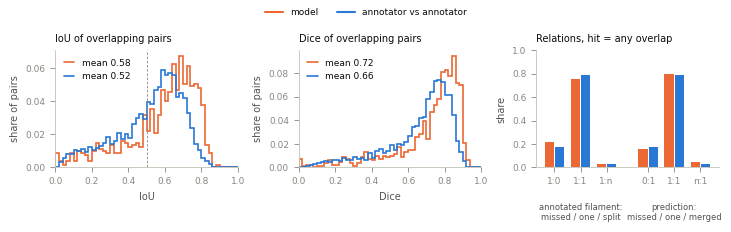

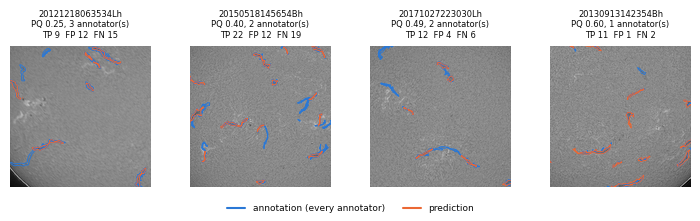

In [10]:
import matplotlib.pyplot as plt
import numpy as np

from filament import viz

if model_analysis is None:
    print(f"no figures: configuration {pipe.configuration!r} has no model predictions on the report half "
          "(stage 7)")
else:
    viz.apply_style()
    fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.2), constrained_layout=True)
    viz.plot_distributions(axes, {"model": model_analysis, "annotator vs annotator": humans_all})
    fig.savefig(OUTPUT_DIR / "distributions.png")
    plt.show()

    per_image = model_analysis.pq_by("stem").set_index("stem")
    annotators = gt.groupby("stem")["record_id"].nunique()
    available = [stem for stem in FIGURE_STEMS if (TRAIN_IMAGES / f"{stem}.jpeg").is_file()]
    if not available:
        print("overlays skipped: the training images are not in place")
    else:
        fig, axes = plt.subplots(1, len(available), figsize=(1.8 * len(available), 2.1),
                                 constrained_layout=True)
        for ax, stem in zip(np.atleast_1d(axes), available):
            annotations = gt.loc[gt["stem"] == stem, "segmentation_rle"].tolist()
            viz.draw_overlay(ax, load_image(TRAIN_IMAGES / f"{stem}.jpeg"), annotations,
                             validation.get(stem, []), viz.densest_window(annotations))
            row = per_image.loc[stem]
            ax.set_title(f"{stem}\nPQ {row.pq:.2f}, {annotators[stem]} annotator(s)\n"
                         f"TP {int(row.tp)}  FP {int(row.fp)}  FN {int(row.fn)}", fontsize=6)
        fig.legend(handles=viz.legend_handles({"annotation (every annotator)": viz.ANNOTATION_COLOR,
                                               "prediction": viz.PREDICTION_COLOR}),
                   loc="outside lower center", ncol=2)
        fig.savefig(OUTPUT_DIR / "overlays.png")
        plt.show()